In [1]:
"""
WESAD Binary Stress Detection - Notebook 1: Data Acquisition & Loading
========================================================================
STRICT COMPLIANCE: All fixed values must be used exactly as specified.
No architectural decisions may be changed or inferred.
"""

# ============================================================================
# FIXED CONFIGURATION - DO NOT MODIFY
# ============================================================================

CONFIG = {
    # Task Configuration
    'task_type': 'binary_classification',  # FIXED
    'stress_label': 1,  # FIXED
    'non_stress_label': 0,  # FIXED
    
    # Class Mapping
    'label_mapping': {
        'baseline': 0,      # Non-Stress
        'amusement': 0,     # Non-Stress
        'stress': 1,        # Stress
        'meditation': None  # Not used
    },
    
    # Modalities (Chest-based only)
    'modalities': {
        'chest_signals': ['ECG', 'EDA', 'EMG', 'Respiration', 'Temperature'],  # FIXED
        'use_wrist': False  # FIXED: Wrist signals are NOT used
    },
    
    # Dataset
    'dataset_name': 'WESAD',  # FIXED
    'num_subjects': 15,  # FIXED
    'subject_ids': list(range(2, 18)),  # Subjects S2 to S17 (15 subjects)
}

In [2]:
# ============================================================================
# IMPORTS
# ============================================================================

import os
import pickle
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [3]:
# ============================================================================
# DATASET PATH CONFIGURATION
# ============================================================================

# TODO: Set your WESAD dataset path
WESAD_PATH ="C:\\Users\\yomna.000\\Downloads\\grad project\\WESAD"  # TODO: Update this path

def verify_dataset_structure(base_path):
    """
    Verify WESAD dataset structure and return subject paths.
    
    Expected structure:
    WESAD/
    ├── S2/
    │   └── S2.pkl
    ├── S3/
    │   └── S3.pkl
    ...
    └── S17/
        └── S17.pkl
    """
    base_path = Path(base_path)
    
    if not base_path.exists():
        raise FileNotFoundError(f"Dataset path does not exist: {base_path}")
    
    subject_paths = {}
    missing_subjects = []
    
    for subject_id in CONFIG['subject_ids']:
        subject_name = f"S{subject_id}"
        subject_dir = base_path / subject_name
        subject_file = subject_dir / f"{subject_name}.pkl"
        
        if subject_file.exists():
            subject_paths[subject_name] = subject_file
        else:
            missing_subjects.append(subject_name)
    
    if missing_subjects:
        print(f"Warning: Missing subjects: {missing_subjects}")
    
    print(f"Found {len(subject_paths)} subjects")
    return subject_paths

In [4]:
# ============================================================================
# DATA LOADING FUNCTIONS
# ============================================================================

def load_subject_data(subject_path):
    """
    Load data for a single subject from WESAD .pkl file.
    
    Returns:
        dict: Subject data containing 'signal', 'label', and 'subject' info
    """
    with open(subject_path, 'rb') as f:
        data = pickle.load(f, encoding='latin1')
    return data


def extract_chest_signals(subject_data):
    """
    Extract chest-based signals only (FIXED modalities).
    
    WESAD chest signal structure:
    - ECG: index 0
    - EDA: index 1
    - EMG: index 2
    - Temp: index 3
    - Resp: index 4
    
    Returns:
        dict: Dictionary with signal names as keys and numpy arrays as values
    """
    chest = subject_data['signal']['chest']
    
    signals = {
        'ECG': chest['ECG'].squeeze(),
        'EDA': chest['EDA'].squeeze(),
        'EMG': chest['EMG'].squeeze(),
        'Temperature': chest['Temp'].squeeze(),
        'Respiration': chest['Resp'].squeeze(),
    }
    
    return signals


def extract_labels(subject_data):
    """
    Extract and map labels to binary classification.
    
    WESAD label encoding:
    - 0: Not defined
    - 1: Baseline → 0 (Non-Stress)
    - 2: Stress → 1 (Stress)
    - 3: Amusement → 0 (Non-Stress)
    - 4: Meditation → Not used
    
    Returns:
        numpy.ndarray: Binary labels (0 = Non-Stress, 1 = Stress)
    """
    labels = subject_data['label']
    
    # Create binary labels
    binary_labels = np.full_like(labels, -1, dtype=np.int32)
    
    # Map: Baseline (1) → 0
    binary_labels[labels == 1] = 0
    
    # Map: Stress (2) → 1
    binary_labels[labels == 2] = 1
    
    # Map: Amusement (3) → 0
    binary_labels[labels == 3] = 0
    
    # Meditation (4) and undefined (0) remain -1 (to be filtered)
    
    return binary_labels

def load_all_subjects(subject_paths):
    """
    Load data from all available subjects.
    
    Returns:
        dict: Dictionary with subject IDs as keys and processed data as values
    """
    all_data = {}
    
    for subject_id, subject_path in subject_paths.items():
        print(f"Loading {subject_id}...", end=' ')
        
        try:
            # Load raw data
            subject_data = load_subject_data(subject_path)
            
            # Extract chest signals
            signals = extract_chest_signals(subject_data)
            
            # Extract and map labels
            labels = extract_labels(subject_data)
            
            # Store processed data
            all_data[subject_id] = {
                'signals': signals,
                'labels': labels,
                'original_sampling_rate': 700,  # WESAD chest sampling rate
            }
            
            print(f"✓ ({len(labels)} samples)")
            
        except Exception as e:
            print(f"✗ Error: {e}")
    
    return all_data

In [5]:
# ============================================================================
# DATA INSPECTION FUNCTIONS
# ============================================================================

def inspect_subject_data(subject_id, data):
    """Display basic statistics for a subject's data."""
    print(f"\n{'='*60}")
    print(f"Subject: {subject_id}")
    print(f"{'='*60}")
    
    signals = data['signals']
    labels = data['labels']
    
    # Signal shapes
    print("\nSignal Shapes:")
    for signal_name, signal_data in signals.items():
        print(f"  {signal_name:15s}: {signal_data.shape}")
    
    # Label distribution
    print("\nLabel Distribution:")
    valid_labels = labels[labels != -1]
    unique, counts = np.unique(valid_labels, return_counts=True)
    for label, count in zip(unique, counts):
        label_name = "Stress" if label == 1 else "Non-Stress"
        print(f"  {label_name:15s} ({label}): {count:8d} samples ({count/len(valid_labels)*100:.1f}%)")
    
    print(f"  {'Undefined':15s} (-1): {np.sum(labels == -1):8d} samples")
    print(f"\nTotal samples: {len(labels)}")

def plot_signal_sample(subject_id, data, duration_seconds=60, start_second=0):
    """
    Plot a sample of signals for visual inspection.
    
    Args:
        subject_id: Subject identifier
        data: Subject data dictionary
        duration_seconds: Duration to plot (default 60 seconds)
        start_second: Starting point in seconds
    """
    signals = data['signals']
    labels = data['labels']
    sampling_rate = data['original_sampling_rate']
    
    start_idx = start_second * sampling_rate
    end_idx = start_idx + (duration_seconds * sampling_rate)
    
    fig, axes = plt.subplots(6, 1, figsize=(15, 10))
    fig.suptitle(f'Subject {subject_id} - Signal Sample ({duration_seconds}s)', fontsize=14)
    
    time_axis = np.arange(start_idx, end_idx) / sampling_rate
    
    # Plot each signal
    for idx, (signal_name, signal_data) in enumerate(signals.items()):
        axes[idx].plot(time_axis, signal_data[start_idx:end_idx], linewidth=0.5)
        axes[idx].set_ylabel(signal_name)
        axes[idx].grid(True, alpha=0.3)
    
    # Plot labels
    axes[5].plot(time_axis, labels[start_idx:end_idx], linewidth=0.5, color='red')
    axes[5].set_ylabel('Label')
    axes[5].set_xlabel('Time (seconds)')
    axes[5].set_yticks([-1, 0, 1])
    axes[5].set_yticklabels(['Undefined', 'Non-Stress', 'Stress'])
    axes[5].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [6]:
# ============================================================================
# DATA SAVING FUNCTIONS
# ============================================================================

def save_processed_data(data, output_dir='processed_data'):
    """
    Save processed data for use in subsequent notebooks.
    
    Args:
        data: Dictionary of processed subject data
        output_dir: Output directory path
    """
    output_path = Path(output_dir)
    output_path.mkdir(exist_ok=True)
    
    output_file = output_path / 'raw_loaded_data.pkl'
    
    with open(output_file, 'wb') as f:
        pickle.dump({
            'data': data,
            'config': CONFIG
        }, f)
    
    print(f"\nData saved to: {output_file}")
    print(f"Total subjects: {len(data)}")

WESAD BINARY STRESS DETECTION - NOTEBOOK 1: DATA ACQUISITION

[1/4] Verifying dataset structure...
Found 15 subjects

[2/4] Loading subject data...
Loading S2... ✓ (4255300 samples)
Loading S3... ✓ (4545100 samples)
Loading S4... ✓ (4496100 samples)
Loading S5... ✓ (4380600 samples)
Loading S6... ✓ (4949700 samples)
Loading S7... ✓ (3666600 samples)
Loading S8... ✓ (3826200 samples)
Loading S9... ✓ (3656100 samples)
Loading S10... ✓ (3847200 samples)
Loading S11... ✓ (3663100 samples)
Loading S13... ✓ (3875900 samples)
Loading S14... ✓ (3883600 samples)
Loading S15... ✓ (3676400 samples)
Loading S16... ✓ (3941700 samples)
Loading S17... ✓ (4144000 samples)

[3/4] Inspecting data...

Subject: S2

Signal Shapes:
  ECG            : (4255300,)
  EDA            : (4255300,)
  EMG            : (4255300,)
  Temperature    : (4255300,)
  Respiration    : (4255300,)

Label Distribution:
  Non-Stress      (0):  1054200 samples (71.0%)
  Stress          (1):   430500 samples (29.0%)
  Undefined  

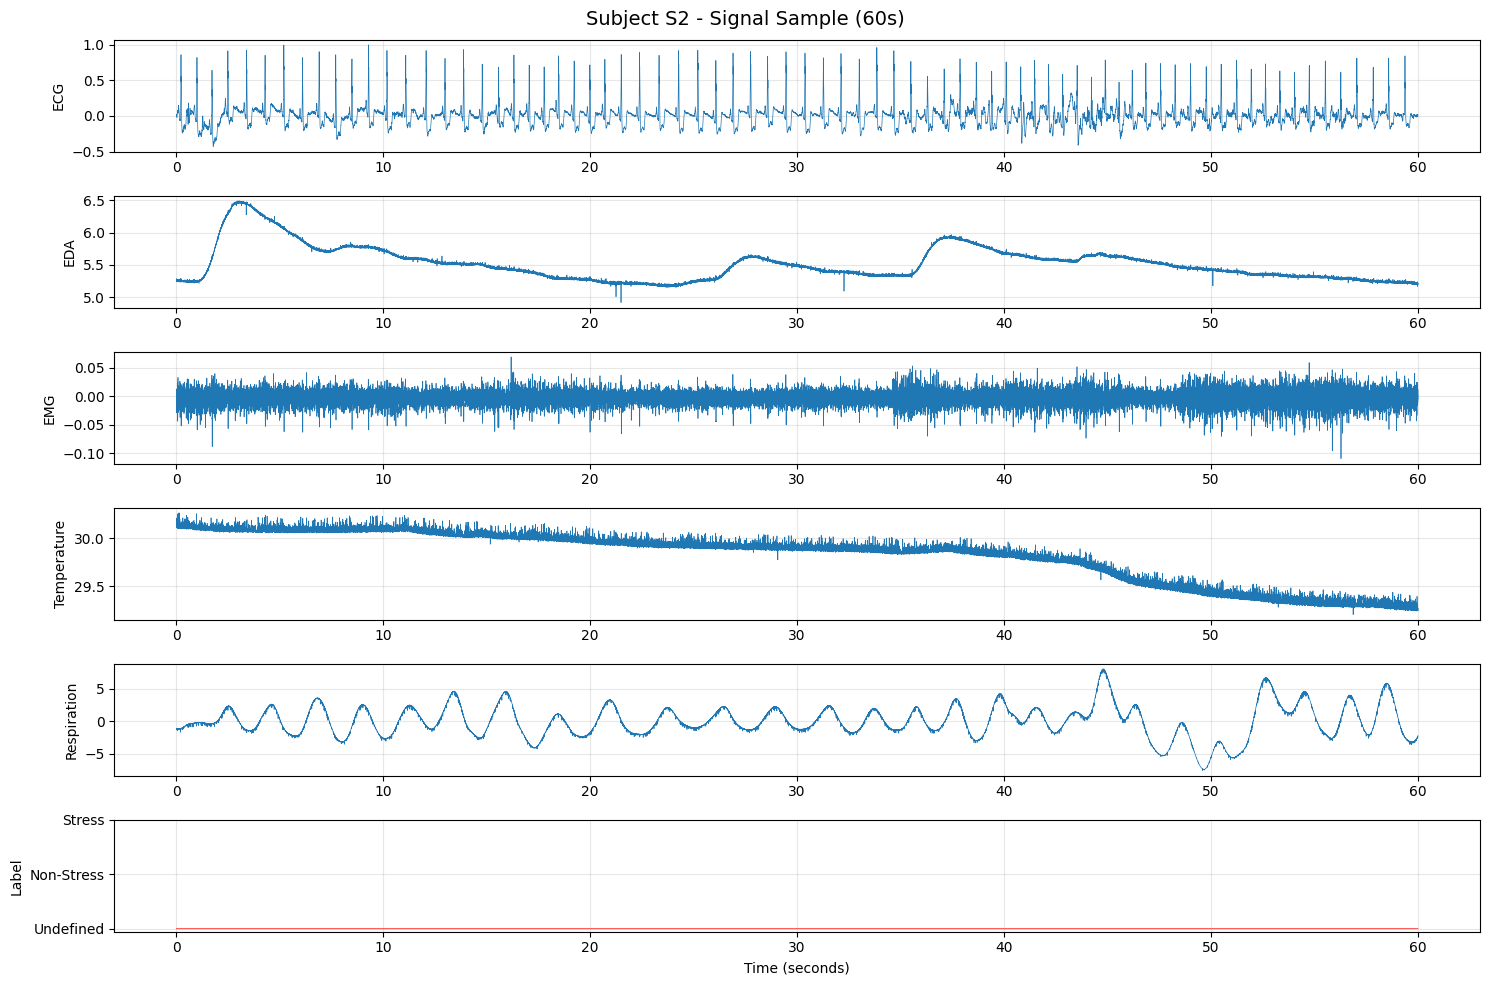


[5/5] Saving processed data...

Data saved to: processed_data\raw_loaded_data.pkl
Total subjects: 15

✓ Notebook 1 Complete - Proceed to Notebook 2 (Preprocessing)


In [7]:
# ============================================================================
# MAIN EXECUTION
# ============================================================================

if __name__ == "__main__":
    print("="*70)
    print("WESAD BINARY STRESS DETECTION - NOTEBOOK 1: DATA ACQUISITION")
    print("="*70)
    
    # Step 1: Verify dataset structure
    print("\n[1/4] Verifying dataset structure...")
    subject_paths = verify_dataset_structure(WESAD_PATH)
    
    # Step 2: Load all subjects
    print("\n[2/4] Loading subject data...")
    all_data = load_all_subjects(subject_paths)
    
    # Step 3: Inspect first subject
    print("\n[3/4] Inspecting data...")
    first_subject = list(all_data.keys())[0]
    inspect_subject_data(first_subject, all_data[first_subject])
    
    # Optional: Visualize signals
    print("\n[4/4] Visualizing sample signals...")
    plot_signal_sample(first_subject, all_data[first_subject], duration_seconds=60)
    
    # Step 4: Save processed data
    print("\n[5/5] Saving processed data...")
    save_processed_data(all_data)
    
    print("\n" + "="*70)
    print("✓ Notebook 1 Complete - Proceed to Notebook 2 (Preprocessing)")
    print("="*70)

In [8]:
s = all_data['S2']['signals']
for k, v in s.items():
    print(k, v.shape)

ECG (4255300,)
EDA (4255300,)
EMG (4255300,)
Temperature (4255300,)
Respiration (4255300,)
